In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

data = {
    'X': [1, 2, 3, 4, 5, 6, 7, 8, 9],
    'Y': [5, 7, 9, 11, 50, 15, 17, 19, 21]
}

df = pd.DataFrame(data)

print(df)

   X   Y
0  1   5
1  2   7
2  3   9
3  4  11
4  5  50
5  6  15
6  7  17
7  8  19
8  9  21


In [2]:
X = df[['X']]
y = df['Y']

In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 5
Validation samples: 2
Testing samples: 2


In [4]:
models = {
    'OLS': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.1)
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    # Predictions
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    # Calculate MSE
    train_mse = mean_squared_error(y_train, train_pred)
    val_mse = mean_squared_error(y_val, val_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    results.append({
        'Model': name,
        'Training MSE': train_mse,
        'Validation MSE': val_mse,
        'Testing MSE': test_mse
    })

comparison = pd.DataFrame(results)

print(comparison.round(3))

   Model  Training MSE  Validation MSE  Testing MSE
0    OLS       214.791          37.643      128.445
1  Ridge       214.800          37.000      132.500
2  Lasso       214.794          37.320      130.465


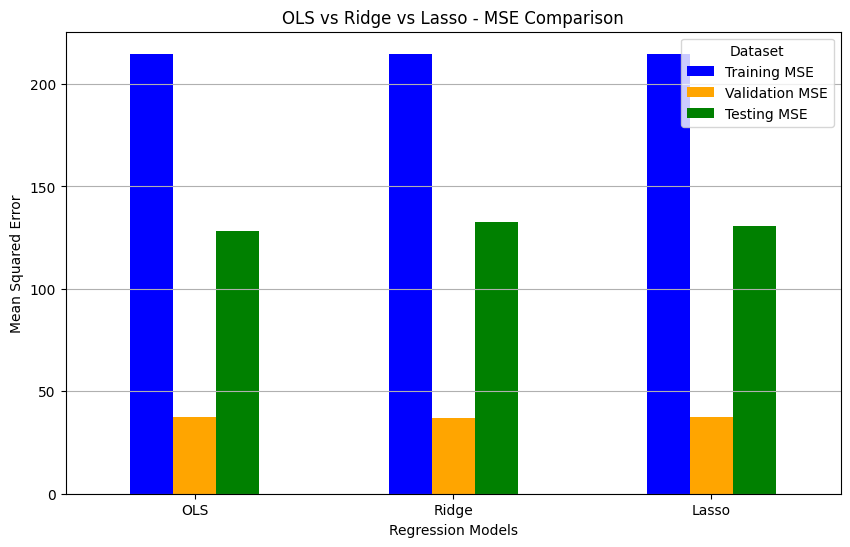

In [5]:
comparison.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6),
    color=['blue', 'orange', 'green']
)

plt.title('OLS vs Ridge vs Lasso - MSE Comparison')
plt.ylabel('Mean Squared Error')
plt.xlabel('Regression Models')

plt.xticks(rotation=0)
plt.legend(title='Dataset')
plt.grid(axis='y')
plt.show()

In [6]:
best_model = comparison.loc[
    comparison['Validation MSE'].idxmin()
]

print("Best Model:", best_model['Model'])
print("Training MSE:", best_model['Training MSE'])
print("Validation MSE:", best_model['Validation MSE'])
print("Testing MSE:", best_model['Testing MSE'])

Best Model: Ridge
Training MSE: 214.8
Validation MSE: 37.00000000000004
Testing MSE: 132.50000000000009
